# HS524M Test 2, Question 2 — Kolkata NO₂ and women aged 15–49 (2020)

**Question:** What share of women aged 15–49 reside in the highest quartile of satellite-observed annual tropospheric NO₂ within the Kolkata study boundary?

Run cells in order. The notebook creates an annual map, a high-NO₂ population map, a 12-month GIF, CSV summaries and a ready-to-host `index.html` in one output folder. The webpage assets use embedded raster overlays and a relative GIF link; upload the **entire output folder**, preserving filenames. An internet connection is required for the basemap and Leaflet controls. Replace the Google Earth Engine project ID below if necessary and complete Earth Engine authentication when prompted.

**Scope:** This answers Question 2, row 2. Question 1 requires your QField waste-bin observations and photos, which were not provided here.

In [8]:
%pip install -q earthengine-api geemap folium pandas pillow requests

Note: you may need to restart the kernel to use updated packages.


In [9]:
from pathlib import Path
from datetime import date
from calendar import month_name
from html import escape
import base64
import io
import json

import ee
import folium
import geemap
import pandas as pd
import requests
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Image as NotebookImage

EE_PROJECT = "urban-sem-iii"  
OUTPUT_DIR = Path.cwd() / "kolkata_no2_web"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
YEAR = 2020
START, END = "2020-01-01", "2021-01-01"
NO2_BAND = "tropospheric_NO2_column_number_density"
SCALE_NO2 = 1113 
NO2_VIS = {"min": 0, "max": 0.0002,
           "palette": ["253494", "2c7fb8", "41b6c4", "a1dab4", "ffffcc", "fe9929", "cc4c02"]}

try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    print("Earth Engine authentication is required in this environment.")
    ee.Initialize
print("Earth Engine initialized. Outputs:", OUTPUT_DIR)

Earth Engine initialized. Outputs: C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web


## 1. Boundary and sources

The boundary is the **Kolkata ADM2 district polygon from FAO GAUL 2015 level 2**, which can differ from the Kolkata Municipal Corporation area. This choice defines the denominator and all maps; it must be stated on the webpage. Sources: [GAUL 2015](https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2), [Sentinel-5P OFFL NO₂](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S5P_OFFL_L3_NO2), [WorldPop 2020 age–sex](https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop_age_sex).

In [10]:
city = (ee.FeatureCollection("FAO/GAUL/2015/level2")
        .filter(ee.Filter.eq("ADM0_NAME", "India"))
        .filter(ee.Filter.eq("ADM1_NAME", "West Bengal"))
        .filter(ee.Filter.eq("ADM2_NAME", "Kolkata")))
city_count = city.size().getInfo()
if city_count != 1:
    raise ValueError(f"Expected one GAUL Kolkata feature; got {city_count}. Inspect GAUL names.")
region = city.geometry()
geojson = city.getInfo()
coords = region.bounds(maxError=1).coordinates().getInfo()[0]
west, east = min(p[0] for p in coords), max(p[0] for p in coords)
south, north = min(p[1] for p in coords), max(p[1] for p in coords)
map_bounds = [[south, west], [north, east]]
print(f"GAUL district area: {region.area(maxError=1).divide(1e6).getInfo():.1f} km²")

C:\Users\jrana\miniconda3\envs\uisa_2026\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


GAUL district area: 91.8 km²


## 2. Annual and monthly NO₂

Filter each source image by cloud fraction ≤0.30, then average valid NO₂ observations. The source catalog already applies a retrieval validity filter to NO₂. The 75th percentile uses the annual **NO₂ pixel distribution within the selected district**, at the native S5P grid and an approximately 1.1 km analysis scale. Its threshold is relative to Kolkata in 2020, not a health standard. Monthly composites use exactly the same visual scale as the annual composite.

In [11]:
source = (ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
          .filterDate(START, END).filterBounds(region))
source_count = source.size().getInfo()
if source_count == 0:
    raise ValueError("No Sentinel-5P images intersect the study area in 2020.")

def mask_cloud(image):
    return (image.select(NO2_BAND)
            .updateMask(image.select("cloud_fraction").lte(0.30))
            .copyProperties(image, ["system:time_start"]))

no2 = source.map(mask_cloud)
no2_projection = ee.Image(no2.first()).select(NO2_BAND).projection()
annual = (no2.mean().rename("NO2")
          .setDefaultProjection(no2_projection).clip(region))
annual_stats = annual.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.percentile([75]), sharedInputs=True),
    geometry=region, crs=no2_projection, scale=SCALE_NO2,
    maxPixels=1e9, tileScale=4).getInfo()
print("Annual statistics:", annual_stats)
annual_mean = annual_stats.get("NO2_mean")
q75 = annual_stats.get("NO2_p75")
if annual_mean is None or q75 is None:
    raise ValueError("Missing annual NO₂ statistics; inspect image coverage and reduceRegion output.")
print(f"Annual city mean: {annual_mean:.8f} mol/m²; pixelwise 75th percentile: {q75:.8f} mol/m²")
high_mask = annual.gte(ee.Number(q75)).And(annual.mask()).rename("high_no2")

monthly_images, monthly_rows = [], []
for month in range(1, 13):
    d0 = date(YEAR, month, 1)
    d1 = date(YEAR + (month == 12), month % 12 + 1, 1)
    subset = no2.filterDate(d0.isoformat(), d1.isoformat())
    n = subset.size().getInfo()
    if n == 0:
        monthly_rows.append({"Month": month_name[month], "Images": n, "Mean_NO2_mol_m2": None})
        continue
    image = subset.mean().rename("NO2").setDefaultProjection(no2_projection).clip(region)
    value = image.reduceRegion(ee.Reducer.mean(), region, crs=no2_projection,
                               scale=SCALE_NO2, maxPixels=1e9, tileScale=4).get("NO2").getInfo()
    monthly_rows.append({"Month": month_name[month], "Images": n, "Mean_NO2_mol_m2": value})
    if value is not None:
        monthly_images.append((month, image))
monthly_df = pd.DataFrame(monthly_rows)
monthly_df.to_csv(OUTPUT_DIR / "kolkata_monthly_no2_2020.csv", index=False)
display(monthly_df)
if len(monthly_images) < 2:
    raise ValueError("Fewer than two valid monthly composites; cannot make a meaningful GIF.")

Annual statistics: {'NO2_mean': 8.349077134757768e-05, 'NO2_p75': 8.689957516570357e-05}
Annual city mean: 0.00008349 mol/m²; pixelwise 75th percentile: 0.00008690 mol/m²


,Month,Images,Mean_NO2_mol_m2
0,January,439,0.000128
1,February,407,0.000113
2,March,440,0.000072
3,April,425,0.000052
4,May,438,0.000046
5,June,425,0.000057
6,July,439,0.000039
7,August,437,0.000046
8,September,425,0.000042
9,October,440,0.000055


## 3. Population residing in relatively high NO₂ areas

WorldPop age bins `F_15` through `F_45` cover ages 15–49. A coarse Sentinel-5P class is assigned by **nearest neighbour to the centres of WorldPop cells**; the finer cells do not reveal subpixel NO₂ variation. Population totals are summed on the native WorldPop grid within GAUL Kolkata. The exposure share uses **all estimated women aged 15–49 in that district** as denominator. Missing NO₂ coverage remains outside the high group and is separately reported.

In [12]:
worldpop_collection = (ee.ImageCollection("WorldPop/GP/100m/pop_age_sex")
                       .filter(ee.Filter.eq("country", "IND"))
                       .filter(ee.Filter.eq("year", 2020)))
worldpop_count = worldpop_collection.size().getInfo()
if worldpop_count != 1:

    print("Filtered WorldPop count:", worldpop_count)
    candidate = ee.Image("WorldPop/GP/100m/pop_age_sex/IND_2020")
    print("Candidate properties:", candidate.toDictionary(["country", "year", "system:index"]).getInfo())
    worldpop = candidate
else:
    worldpop = ee.Image(worldpop_collection.first())

female_bands = [f"F_{a}" for a in range(15, 50, 5)]
missing = set(female_bands) - set(worldpop.bandNames().getInfo())
if missing:
    raise ValueError(f"Required WorldPop bands are missing: {sorted(missing)}")
women = worldpop.select(female_bands).reduce(ee.Reducer.sum()).rename("women_15_49")
pop_projection = worldpop.select("F_15").projection()
pop_scale = pop_projection.nominalScale().getInfo()

high_on_pop_grid = high_mask.reproject(pop_projection)
valid_on_pop_grid = annual.mask().reproject(pop_projection)
exposed_image = women.updateMask(high_on_pop_grid).rename("exposed_women")
valid_women_image = women.updateMask(valid_on_pop_grid).rename("women_valid_no2")
combined = (women.addBands(exposed_image).addBands(valid_women_image))
counts = combined.reduceRegion(reducer=ee.Reducer.sum(), geometry=region,
                               crs=pop_projection, scale=pop_scale,
                               maxPixels=1e10, tileScale=8).getInfo()
total_women = counts.get("women_15_49")
exposed_women = counts.get("exposed_women") or 0
valid_women = counts.get("women_valid_no2") or 0
if total_women is None or total_women <= 0:
    raise ValueError(f"Invalid WorldPop sum: {counts}")
share = 100 * exposed_women / total_women
coverage_share = 100 * valid_women / total_women
if exposed_women > total_women + 1e-6:
    raise AssertionError("Exposed population exceeds district total; inspect grid alignment.")

summary = pd.DataFrame([
    ("Study area", "FAO GAUL 2015 ADM2 Kolkata district"),
    ("Year", YEAR),
    ("Annual city mean NO₂ (mol/m²)", f"{annual_mean:.8f}"),
    ("High NO₂ threshold, pixel 75th percentile (mol/m²)", f"{q75:.8f}"),
    ("Women aged 15–49, district (WorldPop estimate)", round(total_women)),
    ("Women aged 15–49 in high NO₂ cells (estimate)", round(exposed_women)),
    ("Exposure share of all district women aged 15–49 (%)", f"{share:.2f}"),
    ("Women with valid annual NO₂ data (%)", f"{coverage_share:.2f}"),
], columns=["Indicator", "Value"])
summary.to_csv(OUTPUT_DIR / "kolkata_women_no2_exposure_2020.csv", index=False)
display(summary)

,Indicator,Value
0,Study area,FAO GAUL 2015 ADM2 Kolkata district
1,Year,2020
2,Annual city mean NO₂ (mol/m²),0.00008349
3,"High NO₂ threshold, pixel 75th percentile (mol...",0.00008690
4,"Women aged 15–49, district (WorldPop estimate)",821208
5,Women aged 15–49 in high NO₂ cells (estimate),177843
6,Exposure share of all district women aged 15–4...,21.66
7,Women with valid annual NO₂ data (%),100.00


## 4. Portable maps and GIF

These output maps embed their NO₂ image overlays and boundary geometry in the HTML. The 12 monthly map frames form the required animated GIF; no separate monthly graph is produced. They therefore do not depend on temporary Earth Engine map tiles after upload. The OpenStreetMap basemap and Leaflet scripts still require normal internet access. Each frame uses the same 0–0.0002 mol/m² scale; values above that limit saturate on the display only. Numeric statistics use the original, unclamped data.

In [13]:
import ee
import folium
from pathlib import Path
from IPython.display import display


OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



def get_boundary_bounds(obj):

    coordinates = []

    def extract(item):

        if isinstance(item, (list, tuple)):

            if (
                len(item) >= 2
                and isinstance(item[0], (int, float))
                and isinstance(item[1], (int, float))
            ):
                coordinates.append(
                    (item[0], item[1])
                )

            else:
                for value in item:
                    extract(value)

        elif isinstance(item, dict):

            if "coordinates" in item:
                extract(item["coordinates"])

            elif "geometry" in item:
                extract(item["geometry"])

            elif "features" in item:
                extract(item["features"])

    extract(obj)

    if not coordinates:
        raise ValueError("Boundary coordinates not found.")

    lons = [p[0] for p in coordinates]
    lats = [p[1] for p in coordinates]

    return [
        [min(lats), min(lons)],
        [max(lats), max(lons)]
    ]


boundary_bounds = get_boundary_bounds(geojson)

center_lat = (
    boundary_bounds[0][0] +
    boundary_bounds[1][0]
) / 2

center_lon = (
    boundary_bounds[0][1] +
    boundary_bounds[1][1]
) / 2


def add_ee_layer(
    m,
    image,
    vis,
    layer_name,
    opacity=0.85
):

    map_id = image.getMapId(vis)

    tile_url = map_id["tile_fetcher"].url_format

    folium.TileLayer(
        tiles=tile_url,
        attr="Google Earth Engine",
        name=layer_name,
        overlay=True,
        control=True,
        opacity=opacity,
        show=True
    ).add_to(m)


def add_boundary(m):

    folium.GeoJson(
        geojson,
        name="Kolkata Municipal Boundary",

        style_function=lambda feature: {
            "color": "#111111",
            "weight": 2.5,
            "fillOpacity": 0
        },

        tooltip="Kolkata Municipal Boundary"

    ).add_to(m)



annual_band = (
    annual
    .select(0)
    .rename("NO2")
)

NO2_MIN = 0.00007246988628668167
NO2_MAX = 0.00009036459204960462

NO2_VIS = {

    "min": NO2_MIN,

    "max": NO2_MAX,

    "palette": [
        "253494",
        "2c7fb8",
        "41b6c4",
        "a1dab4",
        "ffffb2",
        "fe9929",
        "cc4c02",
        "800026"
    ]
}



annual_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles="OpenStreetMap",
    control_scale=True
)

add_ee_layer(
    annual_map,
    annual_band.clip(region),
    NO2_VIS,
    "2020 Annual Mean NO2",
    opacity=0.85
)

add_boundary(annual_map)



annual_legend = f"""
<div style="
position:fixed;
bottom:25px;
right:25px;
left:auto;
z-index:9999;
background:white;
padding:14px;
border:1px solid #777;
border-radius:7px;
font:13px Arial;
width:285px;
">

<b>Kolkata Annual Mean Tropospheric NO2</b>
<br>
<b>Year: 2020</b>
<br>
Unit: mol/m²

<div style="
background:linear-gradient(
90deg,
#253494,
#2c7fb8,
#41b6c4,
#a1dab4,
#ffffb2,
#fe9929,
#cc4c02,
#800026
);
height:17px;
margin:9px 0;
border:1px solid #ddd;
"></div>

<div style="display:flex;justify-content:space-between;">
<span>{NO2_MIN:.7f}</span>
<span>{NO2_MAX:.7f}</span>
</div>

<br>
<span style="color:#253494;">●</span> Lower NO2
<br>
<span style="color:#800026;">●</span> Higher NO2

</div>
"""

annual_map.get_root().html.add_child(
    folium.Element(annual_legend)
)

folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(annual_map)

annual_map.fit_bounds(
    boundary_bounds,
    padding=(30, 30)
)


annual_file = (
    OUTPUT_DIR /
    "kolkata_annual_no2_2020.html"
)

annual_map.save(str(annual_file))

print("MAP 1 CREATED:", annual_file)

display(annual_map)


exposure_display = (
    exposed_image
    .select(0)
    .unmask(0, False)
    .clip(region)
)


exposure_vis = {

    "min": 0,

    "max": 200,

    "palette": [
        "fff7bc",
        "fec44f",
        "fe9929",
        "cc4c02",
        "800026"
    ]
}



south_small = boundary_bounds[0][0] - 0.005
north_small = boundary_bounds[1][0] + 0.005

west_small = boundary_bounds[0][1] - 0.005
east_small = boundary_bounds[1][1] + 0.005

small_bounds = [
    [south_small, west_small],
    [north_small, east_small]
]


exposure_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=13,
    tiles="OpenStreetMap",
    control_scale=True
)

add_ee_layer(
    exposure_map,
    exposure_display,
    exposure_vis,
    "Women in High NO2 Cells",
    opacity=0.85
)

add_boundary(exposure_map)



exposure_legend = f"""
<div style="
position:fixed;
bottom:25px;
right:25px;
left:auto;
z-index:9999;
background:white;
padding:14px;
border:1px solid #777;
border-radius:7px;
font:13px Arial;
width:300px;
">

<b>Women Aged 15-49 in High-NO2 Cells</b>
<br>
<b>Year: 2020</b>
<br>
WorldPop estimated people per ~100 m cell

<div style="
background:linear-gradient(
90deg,
#fff7bc,
#fec44f,
#fe9929,
#cc4c02,
#800026
);
height:17px;
margin:9px 0;
border:1px solid #ddd;
"></div>

<div style="display:flex;justify-content:space-between;">
<span>0</span>
<span>200 or more</span>
</div>

<br>

<b>High NO2 threshold:</b>
<br>
{q75:.8f} mol/m²

<br><br>

<span style="color:#fff7bc;">●</span>
Zero / outside high-NO2 class

<br>

<span style="color:#fe9929;">●</span>
Higher exposed population

<br>

<span style="color:#800026;">●</span>
Highest exposed population

<br><br>

<small>
Outside high-NO2 cells are displayed as zero.
Zero does not mean nobody lives there.
</small>

</div>
"""

exposure_map.get_root().html.add_child(
    folium.Element(exposure_legend)
)


folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(exposure_map)

exposure_map.fit_bounds(
    small_bounds,
    padding=(15, 15)
)


exposure_file = (
    OUTPUT_DIR /
    "kolkata_women_high_no2_2020.html"
)

exposure_map.save(str(exposure_file))

print("MAP 2 CREATED:", exposure_file)

display(exposure_map)


print("\n========================================")
print("BOTH KOLKATA MAPS CREATED SUCCESSFULLY")
print("========================================")

print("\nMAP 1:")
print(annual_file)

print("\nMAP 2:")
print(exposure_file)



MAP 1 CREATED: C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_annual_no2_2020.html


MAP 2 CREATED: C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_women_high_no2_2020.html



BOTH KOLKATA MAPS CREATED SUCCESSFULLY

MAP 1:
C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_annual_no2_2020.html

MAP 2:
C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_women_high_no2_2020.html


Processing: January
Completed: January
Processing: February
Completed: February
Processing: March
Completed: March
Processing: April
Completed: April
Processing: May
Completed: May
Processing: June
Completed: June
Processing: July
Completed: July
Processing: August
Completed: August
Processing: September
Completed: September
Processing: October
Completed: October
Processing: November
Completed: November
Processing: December
Completed: December
GIF saved: C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_monthly_no2_2020.gif

SUCCESS! YOUR FILES ARE READY.
GIF: C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_monthly_no2_2020.gif
HTML: C:\Users\jrana\Desktop\urban(sem 3)\TEST-2 QUESTION NO-2(HS25M114)\kolkata_no2_web\kolkata_no2_web\kolkata_monthly_no2_2020.html



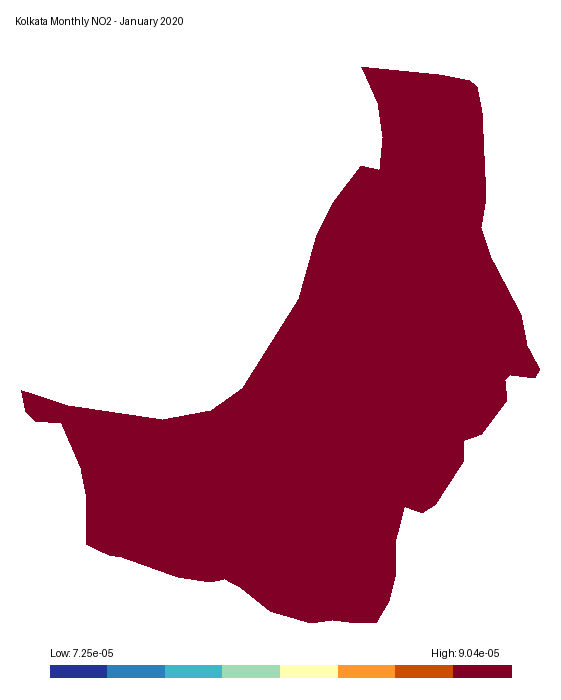

In [14]:


import ee
import requests
import time
import io
import base64
import os
import math

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, HTML

OUTPUT_DIR = Path(OUTPUT_DIR) if "OUTPUT_DIR" in globals() else Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "region" not in globals():
    raise NameError("Kolkata Earth Engine region is missing. Run your boundary preparation cell first.")

if "monthly_images" not in globals():
    raise NameError("monthly_images is missing. Run your monthly NO2 preparation cell first.")

if "NO2_VIS" not in globals():
    raise NameError("NO2_VIS is missing. Define your NO2 visualization settings first.")

if not monthly_images:
    raise ValueError("No monthly images are available.")

month_name = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

boundary_fc = ee.FeatureCollection([
    ee.Feature(region)
])

boundary_image = (
    ee.Image()
    .byte()
    .paint(
        featureCollection=boundary_fc,
        color=1,
        width=2
    )
)

boundary_visual = boundary_image.visualize(
    min=0,
    max=1,
    palette=["FFFFFF"]
)

bounds_info = region.bounds().getInfo()

bounds_coordinates = bounds_info["coordinates"][0]

west = min(point[0] for point in bounds_coordinates)
east = max(point[0] for point in bounds_coordinates)
south = min(point[1] for point in bounds_coordinates)
north = max(point[1] for point in bounds_coordinates)

padding = 0.005

thumb_region = ee.Geometry.Rectangle(
    [
        west - padding,
        south - padding,
        east + padding,
        north + padding
    ],
    proj="EPSG:4326",
    geodesic=False
)

center_lat = (south + north) / 2

aspect = (
    (east - west) *
    math.cos(math.radians(center_lat))
) / (north - south)

MAP_HEIGHT = 600
MAP_WIDTH = max(400, int(MAP_HEIGHT * aspect))

dimensions = f"{MAP_WIDTH}x{MAP_HEIGHT}"

monthly_images_sorted = sorted(
    monthly_images,
    key=lambda item: item[0]
)

gif_frames = []

font = ImageFont.load_default()

for month, monthly_image in monthly_images_sorted:

    print("Processing:", month_name.get(month, str(month)))

    no2_visual = (
        monthly_image
        .clip(region)
        .visualize(**NO2_VIS)
    )

    white_background = ee.Image.constant(
        [255, 255, 255]
    ).visualize(
        min=0,
        max=255
    )

    final_ee_image = (
        white_background
        .blend(no2_visual)
        .blend(boundary_visual)
        .clip(thumb_region)
    )

    params = {
        "region": thumb_region,
        "dimensions": dimensions,
        "format": "png"
    }

    for attempt in range(5):

        try:
            image_url = final_ee_image.getThumbURL(params)

            response = requests.get(
                image_url,
                timeout=120
            )

            response.raise_for_status()

            image_bytes = response.content
            break

        except Exception as error:

            print("Download attempt", attempt + 1, "failed:", error)

            if attempt == 4:
                raise RuntimeError("Monthly image download failed.")

            time.sleep(5 * (attempt + 1))

    map_image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    frame = Image.new(
        "RGB",
        (map_image.width, map_image.height + 100),
        "white"
    )

    frame.paste(map_image, (0, 45))

    draw = ImageDraw.Draw(frame)

    draw.text(
        (15, 15),
        f"Kolkata Monthly NO2 - {month_name.get(month, month)} 2020",
        fill="black",
        font=font
    )

    palette = NO2_VIS["palette"]

    legend_x = 50
    legend_y = map_image.height + 65
    legend_width = map_image.width - 100

    segment_width = legend_width / len(palette)

    for i, color in enumerate(palette):

        rgb = tuple(
            bytes.fromhex(color.lstrip("#"))
        )

        x1 = int(legend_x + i * segment_width)
        x2 = int(legend_x + (i + 1) * segment_width)

        draw.rectangle(
            [x1, legend_y, x2, legend_y + 12],
            fill=rgb
        )

    draw.text(
        (legend_x, legend_y - 18),
        f"Low: {NO2_VIS['min']:.2e}",
        fill="black",
        font=font
    )

    draw.text(
        (map_image.width - 130, legend_y - 18),
        f"High: {NO2_VIS['max']:.2e}",
        fill="black",
        font=font
    )

    gif_frames.append(frame)

    print("Completed:", month_name.get(month, str(month)))

if not gif_frames:
    raise ValueError("No GIF frames were created.")

gif_file = OUTPUT_DIR / "kolkata_monthly_no2_2020.gif"

gif_frames[0].save(
    gif_file,
    save_all=True,
    append_images=gif_frames[1:],
    duration=800,
    loop=0,
    optimize=True
)

print("GIF saved:", gif_file)

with open(gif_file, "rb") as file:
    gif_data = base64.b64encode(file.read()).decode("utf-8")

html_content = f"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>Kolkata Monthly NO2 Animation 2020</title>

<style>
body {{
    font-family: Arial, sans-serif;
    background: #f2f5f7;
    text-align: center;
    padding: 25px;
    margin: 0;
}}

h1 {{
    color: #17365d;
}}

.container {{
    background: white;
    display: inline-block;
    padding: 15px;
    border-radius: 10px;
    max-width: 95%;
    box-shadow: 0 2px 10px rgba(0,0,0,0.15);
}}

img {{
    width: 100%;
    max-width: 850px;
    height: auto;
}}
</style>
</head>

<body>

<h1>Kolkata Monthly NO2 Animation - 2020</h1>

<p>
Monthly variation in Nitrogen Dioxide concentration
across the Kolkata study region.
</p>

<div class="container">
<img src="data:image/gif;base64,{gif_data}"
alt="Kolkata Monthly NO2 Animation">
</div>

<p>Source: Google Earth Engine</p>

</body>
</html>
"""

html_file = OUTPUT_DIR / "kolkata_monthly_no2_2020.html"

with open(html_file, "w", encoding="utf-8") as file:
    file.write(html_content)

print("\nSUCCESS! YOUR FILES ARE READY.")
print("GIF:", gif_file)
print("HTML:", html_file)

display(HTML(html_content))

try:
    os.startfile(str(html_file))
except Exception:
    print("Open the HTML file manually:", html_file)


In [15]:
valid_months = monthly_df.dropna(subset=["Mean_NO2_mol_m2"])
hi = valid_months.loc[valid_months["Mean_NO2_mol_m2"].idxmax()]
lo = valid_months.loc[valid_months["Mean_NO2_mol_m2"].idxmin()]
results_text = f"""Kolkata district, 2020: annual mean tropospheric NO₂ was {annual_mean:.8f} mol/m².
The within-district 75th-percentile threshold was {q75:.8f} mol/m².
Approximately {exposed_women:,.0f} of {total_women:,.0f} estimated women aged 15–49
({share:.2f}%) resided in cells assigned to the relatively high-NO₂ class.
The greatest monthly district mean was {hi['Month']} ({hi['Mean_NO2_mol_m2']:.8f} mol/m²);
the lowest was {lo['Month']} ({lo['Mean_NO2_mol_m2']:.8f} mol/m²).
NO₂ coverage encompassed cells containing {coverage_share:.2f}% of the WorldPop group.
These patterns describe satellite column observations and estimated residential location;
they do not establish individual exposure, ground-level pollution, health effects,
or causal drivers of month-to-month change. Sentinel-5P's approximately 1.1 km grid
is much coarser than WorldPop's approximately 100 m grid, so within-pixel differences
cannot be resolved. Weather, cloud filtering, data gaps and 2020 conditions affect
the estimates. FAO GAUL district boundaries may differ from municipal boundaries.
"""
(OUTPUT_DIR / "results_discussion.txt").write_text(results_text, encoding="utf-8")
print(results_text)

rows_html = "\n".join(f"<tr><th>{escape(str(k))}</th><td>{escape(str(v))}</td></tr>"
                       for k, v in summary.itertuples(index=False, name=None))
page = f"""<!doctype html><html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Kolkata 2020 NO₂ and women aged 15–49</title>
<style>body{{font:16px/1.6 system-ui,sans-serif;color:#17324a;background:#f3f7fa;margin:0}}
main{{max-width:1020px;margin:auto;padding:24px}}h1,h2{{line-height:1.2}}
section{{background:white;padding:20px;margin:20px 0;border-radius:12px;box-shadow:0 2px 12px #abc3d233}}
iframe{{width:100%;height:510px;border:1px solid #c7d4de;border-radius:8px}}
img{{max-width:100%;height:auto;border-radius:8px}}table{{width:100%;border-collapse:collapse}}
th,td{{padding:9px;border-bottom:1px solid #d9e4eb;text-align:left}}th{{width:58%}}
a{{color:#075b8a}}small{{color:#405467}}</style></head><body><main>
<h1>Kolkata: satellite NO₂ and residential population, 2020</h1>
<p>Question: What proportion of women aged 15–49 live in areas with relatively high satellite-observed tropospheric NO₂?</p>
<section><h2>Method</h2><p>FAO GAUL 2015 Kolkata district; 2020 Sentinel-5P OFFL NO₂ observations
masked where cloud fraction exceeds 0.30; annual and monthly pixel means. High means at or above
the city's annual 75th percentile ({q75:.8f} mol/m²). WorldPop 2020 female age bins 15–49
are summed by cell. The coarse NO₂ class is transferred to WorldPop grid cell centres using
nearest-neighbour assignment.</p></section>
<section><h2>Annual tropospheric NO₂</h2><iframe title="Annual NO2 map" src="kolkata_annual_no2_2020.html"></iframe>
<p><a href="kolkata_annual_no2_2020.html">Open full interactive annual map</a></p></section>
<section><h2>Women in relatively high NO₂ areas</h2><iframe title="Women in high NO2 map" src="kolkata_women_high_no2_2020.html"></iframe>
<p><a href="kolkata_women_high_no2_2020.html">Open full interactive exposure map</a></p></section>
<section><h2>Numerical results</h2><table>{rows_html}</table></section>
<section><h2>Monthly NO₂ animation</h2><img src="kolkata_monthly_no2_2020.gif" alt="Animated monthly NO2 map of Kolkata, January to December 2020">
<p>Same map scale in every frame: 0–0.0002 mol/m². Upper values saturate on display.</p>
<p><a href="kolkata_monthly_no2_2020.gif">Open or download the animated GIF</a></p></section>
<section><h2>Interpretation and limitations</h2><p>About {exposed_women:,.0f} of {total_women:,.0f} estimated women
aged 15–49 ({share:.2f}%) resided in relatively high NO₂ areas. The highest monthly district
mean was in {hi['Month']} and the lowest in {lo['Month']}. These results describe residence
and satellite NO₂ columns; they do not measure individual or ground-level exposure.
Sentinel-5P (~1.1 km) is much coarser than WorldPop (~100 m), and cloud filtering,
missing observations and the GAUL district rather than municipal boundary affect interpretation.
The high threshold is local and statistical, not a health standard.</p></section>
<section><h2>Sources</h2><ul>
<li><a href="https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2">FAO GAUL 2015 level 2 district boundary</a></li>
<li><a href="https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S5P_OFFL_L3_NO2">Copernicus Sentinel-5P OFFL NO₂</a></li>
<li><a href="https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop_age_sex">WorldPop 2020 estimated age and sex structure</a></li>
</ul><small>Analysis: 2020; generated from the accompanying notebook.</small></section>
</main></body></html>"""
(OUTPUT_DIR / "index.html").write_text(page, encoding="utf-8")
print("\nFiles ready to upload together:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size/1024:.1f} KB)")

Kolkata district, 2020: annual mean tropospheric NO₂ was 0.00008349 mol/m².
The within-district 75th-percentile threshold was 0.00008690 mol/m².
Approximately 177,843 of 821,208 estimated women aged 15–49
(21.66%) resided in cells assigned to the relatively high-NO₂ class.
The greatest monthly district mean was January (0.00012802 mol/m²);
the lowest was July (0.00003866 mol/m²).
NO₂ coverage encompassed cells containing 100.00% of the WorldPop group.
These patterns describe satellite column observations and estimated residential location;
they do not establish individual exposure, ground-level pollution, health effects,
or causal drivers of month-to-month change. Sentinel-5P's approximately 1.1 km grid
is much coarser than WorldPop's approximately 100 m grid, so within-pixel differences
cannot be resolved. Weather, cloud filtering, data gaps and 2020 conditions affect
the estimates. FAO GAUL district boundaries may differ from municipal boundaries.


Files ready to upload together:
in